# Mandatory assignment 3

**GitHub repository:** *Insert the URL to your repository here.*

## About the assignment

- Complete the assignment individually.
- You may use online resources, including generative AI. Include a statement
  explaining how you used AI, or state that you did not use it.

## Submission

- Submit your completed `assignment3.ipynb` on Canvas by
  **October 23, 2026, at 23:59**.

## Submission requirements

- Create a new repository from the template linked on Canvas (click **Use this
  template** > **Create a new repository**) and implement your solution in your
  GitHub repository.
- Use the TECH2 environment from the course.
- Implement your solution directly in this notebook by inserting code and text
  cells. Do not create additional notebooks or files.
- Include all requested numerical results, figures, and short written answers.
- Give each figure a title, label its axes, and include a legend where needed.
- Before you submit, make sure your GitHub repository is **publicly accessible** and include its URL at the
  top of this notebook.
- Before submission, restart the kernel and run all cells in order. Your notebook
  must run without errors and find the CSV without an absolute file path.

## Hints

- Use the material from lectures and workshops 1–3: functions, loops, NumPy,
  pandas, and Matplotlib.
- Compute group statistics using loops; there is no need to use `groupby()`
  (which we cover in lecture 4), but you can do so if you prefer.

***
## Stock market participation in US households

Who participates in the stock market, and how has participation changed over time?
To answer this question, you will analyze data from the
[Survey of Consumer Finances](https://www.federalreserve.gov/econres/scfindex.htm)
(SCF), a representative survey of US households conducted every three years
from 1989 to 2022.

The file `SCF_10pct.csv` contains a 10% sample of the SCF data. The central variables of
interest for this assignment are:

1. `stocks`, which reports the value of directly held stocks (in US dollars); and
2. `equity`, which reports the value of all equity holdings (in US dollars),
   including direct stock ownership and indirect exposure through mutual funds,
   retirement accounts, and other investment vehicles.

We measure stock market participation in two ways:

- **Direct participation:** a household owns individual stocks (`stocks > 0`).
- **Overall participation:** a household holds equity directly or indirectly
  (`equity > 0`).

For each measure, the *participation rate* is the percentage of households
satisfying that condition. We therefore calculate two rates: the **direct
participation rate** and the **overall participation rate**. Direct participants
are included among overall participants, so the two rates should not be added.

## Data description

| Variable | Description |
|----------|-------------|
| `id` | Unique observation identifier |
| `year` | Survey year |
| `age` | Age of the household reference person |
| `educ` | Education level: `1`: No high school; `2`: High school; `3`: Some college; `4`: Bachelor's or higher |
| `stocks` | Value of directly held individual stocks (in US dollars) |
| `equity` | Total directly and indirectly owned stock equity (in US dollars) |

***
## Part 1 — Data preparation

1. Load `SCF_10pct.csv` into a pandas DataFrame. Print the columns contained in
   the DataFrame and their number of non-missing values.
2. Drop all observations that have missing values for any of the variables listed
   in the table above. For each variable, report how many observations you dropped
   and how many remain.
3. Keep observations with `25 <= age <= 89`, including both endpoints.
   Report how many observations you dropped and how many remain.
4. Create two 0/1 indicator columns:
   - `direct`: 1 if the household participates directly (`stocks > 0`),
     0 otherwise.
   - `overall`: 1 if the household participates directly or indirectly
     (`equity > 0`), 0 otherwise.

## Solution

In [74]:
#part 1

#import libaries
import pandas as pd
import numpy as np

#import data file
file = f'SCF_10pct.csv'

#read the data file
df = pd.read_csv(file)

#displays the columns and the number of missing values in each of them
df.info(show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 5808 entries, 0 to 5807
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   id      5808 non-null   int64  
 1   year    5808 non-null   int64  
 2   age     5808 non-null   int64  
 3   educ    5792 non-null   float64
 4   stocks  5790 non-null   float64
 5   equity  5792 non-null   float64
dtypes: float64(3), int64(3)
memory usage: 272.4 KB


In [75]:
#part 2

#creating a list of columns
columns = ['id', 'year', 'age', 'educ', 'stocks', 'equity']

#looping over the columns and summing up the number of missing observations in each
for column in columns:
    missing = df[column].isna().sum()
    #printing collumn name and the number of missing observations
    print(column, missing)



id 0
year 0
age 0
educ 16
stocks 18
equity 16


In [76]:
for column in columns:    
    #counting the number of total observations
    observations = len(df)
    #dropping rows with missing information
    df = df.dropna(subset = [column])
    #printing the number of dropped observations and remaning ones for each variable
    dropped = observations - len(df)
    print(f'{column}, dropped observations: {dropped}, observations remaning: {len(df)}')



#printing the columns and observations to verify that they align after dropping observations
#the number of observations should be the same for all columns and align with the number of entries
df.info(show_counts= True)

id, dropped observations: 0, observations remaning: 5808
year, dropped observations: 0, observations remaning: 5808
age, dropped observations: 0, observations remaning: 5808
educ, dropped observations: 16, observations remaning: 5792
stocks, dropped observations: 18, observations remaning: 5774
equity, dropped observations: 16, observations remaning: 5758
<class 'pandas.DataFrame'>
Index: 5758 entries, 0 to 5807
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   id      5758 non-null   int64  
 1   year    5758 non-null   int64  
 2   age     5758 non-null   int64  
 3   educ    5758 non-null   float64
 4   stocks  5758 non-null   float64
 5   equity  5758 non-null   float64
dtypes: float64(3), int64(3)
memory usage: 314.9 KB


In [77]:
#part 3

#keeping the rows that satisfies the condition
keep = (df['age'] >= 25) &(df['age'] <= 89)

#updating the existing df to only contain the rows that satisfies the condition
df = df.loc[keep]


In [78]:
#part 4

#creating indicator column for housholds that participate directly
#using a boolean condition to check whether households participate directly
df['direct'] = (df['stocks'] > 0).astype(int)


#creating indicator column for housholds that participate directly or indirectly 

df['overall'] = (df['equity'] > 0).astype(int)


df


,id,year,age,educ,stocks,equity,direct,overall
0,0,1989,35,2.0,0.0,0.0,0,0
1,1,1989,33,2.0,0.0,0.0,0,0
2,2,1989,62,1.0,0.0,0.0,0,0
4,4,1989,70,1.0,0.0,0.0,0,0
5,5,1989,50,1.0,0.0,0.0,0,0
...,...,...,...,...,...,...,...,...
5802,5802,2022,77,3.0,0.0,0.0,0,0
5804,5804,2022,33,3.0,0.0,0.0,0,0
5805,5805,2022,81,2.0,100000.0,100000.0,1,1
5806,5806,2022,58,3.0,40000.0,1212000.0,1,1


## Part 2 - Participation rates

You are now ready to compute the stock market participation rates for the
final sample. You will compute these in two ways: first, by writing a function
that uses a loop to compute the participation rate, and second, by using pandas's
built-in `mean()` method.

1. Write a function `participation_rate(indicator)` that takes a nonempty
   one-dimensional sequence of 0/1 values and returns the fraction of ones
   (in percent).
2. Apply your function to the final sample's `direct` and `overall`
   columns to compute the direct and overall participation rates. Report the
   results.
3. Use pandas's built-in `mean()` method to compute the direct and overall
   participation rates. Report the results.

In [ ]:
#part 1

#creating a function for participation rate for one dimensional sequenses
def participation_rate(indicator):
    #summing all 1s
    one = (df[indicator] == 1).sum()
    #summing all 0s
    zero = (df[indicator] == 0).sum()
    #making the answer into percentage
    percent = one/(one + zero) * 100
    return percent

In [ ]:
#part 2

#calculating direct and overall participation rate with the function and the "direct" and "overall" columns
direct_participation = participation_rate('direct')

overall_participation = participation_rate('overall')

print(f'The direct participation rate is {direct_participation:.2f}%, and the overall perticipation rate is {overall_participation:.2f}%')


The direct participation rate is 16.96%, and the overall perticipation rate is 49.41%


In [93]:
#part 3

#mean gives us the percentage of 1s since there are only one and zero. We then multiply by 100 to get the percentage
direct_participation = df['direct'].mean() * 100

overall_participation = df['overall'].mean() * 100

print(f'The direct participation rate is {direct_participation:.2f}%, and the overall perticipation rate is {overall_participation:.2f}%')


The direct participation rate is 16.96%, and the overall perticipation rate is 49.41%


***
## Part 3 — Participation by education

1. Loop over education categories 1–4. For each category, calculate the direct
   participation rate and the overall participation rate (in percent).
2. Display the results, rounding rates to one decimal place.
3. Create a figure with two subplots, one for each rate, containing bar charts
   of participation rates across education categories.
4. In two or three sentences, describe the education pattern.

In [ ]:
#part 1

#defining lists to store the data
education = []
direct_rates = []
overall_rates = []

#creating a loop for the 4 different categories
for i in range(1,5):
    #storing the amount of observations for each category. Boolean condition
    group = df.loc[df['educ'] == i]
    #adding the education category number to the list (category i)
    education.append(i)
    #adding the direct participation for category i to the list
    direct_rates.append(group['direct'].mean() * 100)
    #adding the overall participation for category i to the list
    overall_rates.append(group['overall'].mean() * 100)



In [ ]:
#part 2
data_dict = {'Direct participation (percent)': direct_rates, 'Overall participation (percent)': overall_rates}

#creating a data frame to display the direct and overall participation rate for each category
#the categories are named according to the table at the top of the assignment
df_1 = (pd.DataFrame(data_dict, index=['No high school', 'High school', 'Some college', 'Bachlors or higher'])).round(1)

#displaying the dataframe
df_1


,Direct participation,Overall participation
No high school,4.4,17.3
High school,11.4,39.9
Some college,13.5,48.3
Bachlors or higher,30.5,73.5


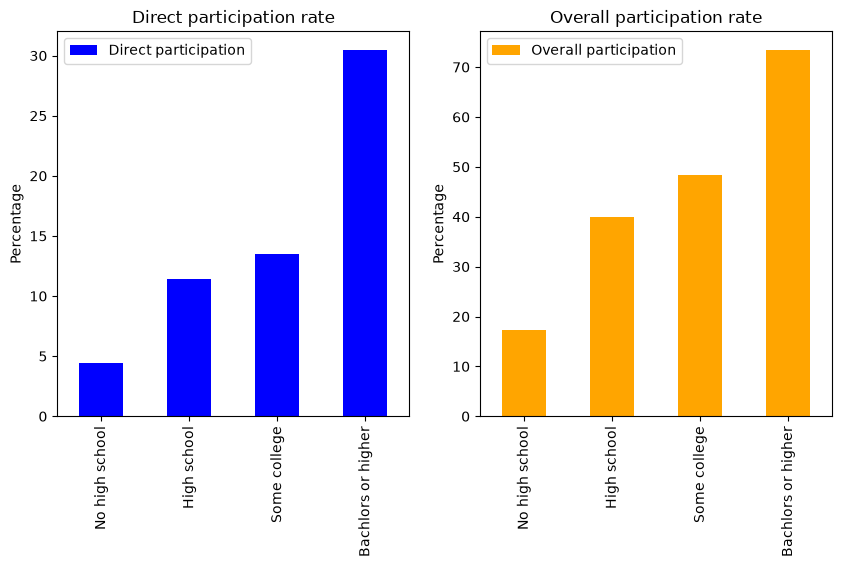

In [ ]:
#part 3

#import requiered library
import matplotlib.pyplot as plt

#creating the two bar charts in seperate plots by using the subplot function (object oriented interface)
fig, axes = plt.subplots(1, 2, sharex = True, figsize = (10, 5))
#creating the charts by using the dataframe df_1
df_1['Direct participation'].plot.bar(ax = axes[0], color='blue')
df_1['Overall participation'].plot.bar(ax = axes[1], color='orange')

#setting appropriate titles
axes[1].set_title('Overall participation rate')
axes[1].set_ylabel('Percentage')
axes[1].set_label('Education level')

axes[0].set_title('Direct participation rate')
axes[0].set_ylabel('Percentage')
axes[0].set_label('Education level')




part 4

The bar-charts above show that the participation, both direct and overall, in the stock market increase wiht a higher education level. Furthermore, the difference between those who have a bachelor's degree or higher and the rest is even more prominant in the direct participation. The overall participation is significantly higher for all caategories.

***
## Part 4 — Participation over time

1. Loop over years. For each year, compute the direct participation rate and the
   overall participation rate.
2. Create a line plot showing both participation rates over time in a single figure.
3. Report the changes from 1989 to 2022 in the direct and overall participation
   rates, both in percentage points.
4. Describe the main time patterns in two or three sentences.

In [ ]:
#part 1

#creating empty lists to store the data
years = []
direct_pp = []
overall_pp = []

#looping over the years between the start and end years from the dataframe
for i in range(1989, 2023):
    #grouping the rows with years = i
    group = df.loc[df['year'] == i]
    #if the year is not representet in any row, the loop skips to the next year. Years without representations are not added.
    if len(group) == 0:
        continue
    #adding year i to the list if it is present in the column
    years.append(i)
    #adding the direct and overall participation for each year to seperate lists
    direct_pp.append(group['direct'].mean() * 100)
    overall_pp.append(group['overall'].mean() * 100)


year
1989    456
1992    459
1995    451
1998    453
2001    449
2004    455
2007    444
2010    449
2013    461
2016    454
2019    452
2022    449
Name: count, dtype: int64


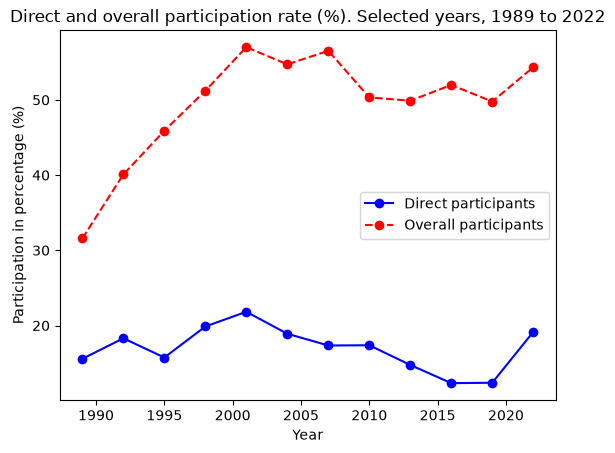

In [ ]:
#part 2

#plotting lines for direct and overall participation. The marker ='o' emphasises which years had observations in the data frame.
plt.plot(years, direct_pp, color = 'blue', ls = '-', marker = 'o', label = 'Direct participants')
plt.plot(years, overall_pp, color = 'red', ls = '--', marker = 'o', label = 'Overall participants')
plt.ylabel('Participation in percentage (%)')
plt.xlabel('Year')
plt.title('Direct and overall participation rate (%). Selected years, 1989 to 2022')
plt.legend(loc = 'center right')

plt.show()


In [ ]:
#part 3

#calculating the change in percentage points by subtraccting the start value from the end value and printing the results
print(f'The change in direct participation from 1989 to 2022 is {direct_pp[-1]-direct_pp[0]:.1f} percentage points')
print(f'The change in overall participation from 1989 to 2022 is {overall_pp[-1]-overall_pp[0]:.1f} percentage points')

The change in direct participation from 1989 to 2022 is 3.6 percentage points
The change in overall participation from 1989 to 2022 is 22.8 percentage points


part 4

The change in direct participation has not changes much over the selected period and it appears to have varied some from year to year without a specific trend. However, the overall participation has significantly increased. The increase seem to have happend mainly between 1989 and 2001, and in the years after the overall participation has actually decreased.

***
## AI-use statement

Students must describe their own use of AI here, or state that they did not use it.

In this assignment I have used the course chatbot TECHi. I have used it to understand error messages and to help me understand how to start or elaborate with the tasks. I have always made attemps first, and used the chatbot to help me understand why it is not working. When feeling lost, it has also pointed me to the lectures or workshops that further explain what commands to use. It has given me suggestions for commands to use, but never the anwser to an entire question/part.